<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/Latihan%20Praktikum%2012_Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12.13 Implementasi Python — Neural Network (MLP dengan Keras) pada Dataset Digits



## Praktikum 12.1 Persiapan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)   # agar hasil lebih mudah direproduksi
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Praktikum 12.2 Import Dataset

Dimensi data: (1797, 64) | kelas: [0 1 2 3 4 5 6 7 8 9]


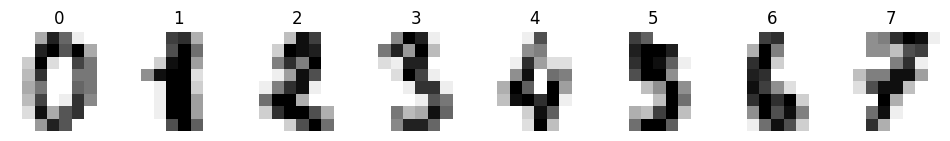

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Dimensi data:", X.shape, "| kelas:", np.unique(y))
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42, stratify=y)

# contoh beberapa gambar
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lab in zip(axes, digits.images[:8], y[:8]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.show()

## Praktikum 12.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Praktikum 12.4 Training Model (Keras Sequential API)

In [4]:
import time
keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")  # 10 kelas angka (0-9)
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

mulai = time.time()
history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=50, batch_size=32, verbose=0)
waktu_mlp = time.time() - mulai
print(f"Waktu pelatihan MLP: {waktu_mlp:.1f} detik")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

Waktu pelatihan MLP: 12.9 detik


## Praktikum 12.5 Evaluasi

In [5]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test: {test_acc:.3f}")

# Pembanding dari buku: Random Forest pada data yang sama
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
mulai = time.time()
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
waktu_rf = time.time() - mulai
acc_rf = accuracy_score(y_test, rf.predict(X_test))
print(f"Akurasi Random Forest: {acc_rf:.3f}  (waktu latih {waktu_rf:.2f} detik)")

Akurasi Test: 0.983
Akurasi Random Forest: 0.969  (waktu latih 1.46 detik)


## Praktikum 12.6 Visualisasi

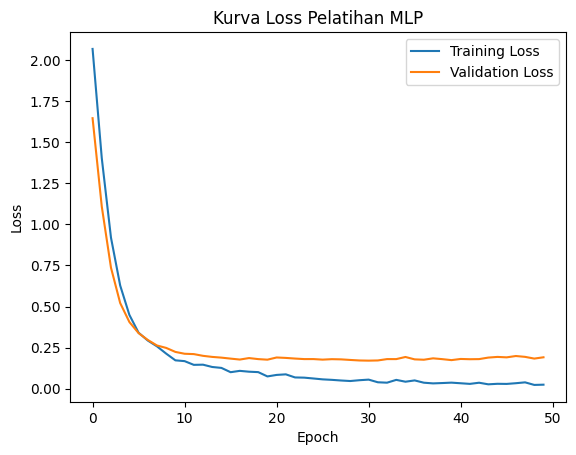

Epoch dengan val_loss terendah: 31 | nilai: 0.1708
val_loss akhir (epoch 50): 0.1913 | training loss akhir: 0.0245
Val accuracy akhir: 0.948


In [6]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss Pelatihan MLP")
plt.legend()
plt.show()

vl = history.history["val_loss"]
print("Epoch dengan val_loss terendah:", int(np.argmin(vl)) + 1, "| nilai:", round(min(vl), 4))
print("val_loss akhir (epoch 50):", round(vl[-1], 4), "| training loss akhir:", round(history.history["loss"][-1], 4))
print("Val accuracy akhir:", round(history.history["val_accuracy"][-1], 3))

### 12.13.1 Interpretasi

Hasil pada eksekusi saya (angka di Colab dapat sedikit berbeda karena keacakan):

- **Akurasi test MLP = 0,983** (354 dari 360 gambar benar), dibanding **Random Forest = 0,969** pada data yang sama. MLP lebih tinggi sekitar 1,4 poin (±5 gambar). Selisih sekecil ini dengan test set 360 sampel belum bisa dipastikan sebagai keunggulan nyata.
- **Biaya komputasi:** MLP butuh sekitar 13 detik untuk 50 epoch, Random Forest (300 pohon) kurang dari 1 detik (±15× lebih cepat; angka waktu bergantung pada mesin). Jadi untuk data digits yang kecil dan bersih, peningkatan akurasi MLP kecil dibanding biaya tambahannya.
- **Kurva loss:** training loss terus turun sampai ±0,02, sementara validation loss berhenti membaik di sekitar epoch 31 (terendah 0,171) lalu naik tipis ke 0,191 pada epoch 50. Kesenjangan 0,02 vs 0,19 menandakan **overfitting ringan**, walaupun dropout 0,3 sudah dipakai. Inilah alasan perlunya early stopping (Praktikum 2).

---
## 12.14 Latihan Praktikum

### Praktikum 1: Eksperimen Arsitektur MLP (Praktikum 12.7)

In [7]:
arsitektur_list = [[32], [64, 32], [128, 64, 32]]
for arsitektur in arsitektur_list:
    keras.utils.set_random_seed(42)
    layers = [keras.layers.Dense(n, activation="relu") for n in arsitektur]
    model = keras.Sequential([keras.Input(shape=(X_train.shape[1],))]
                             + layers
                             + [keras.layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    history = model.fit(X_train, y_train,
                        validation_split=0.2, epochs=30, verbose=0)
    print(f"Arsitektur {arsitektur}: val_accuracy akhir = {history.history['val_accuracy'][-1]:.3f}")

Arsitektur [32]: val_accuracy akhir = 0.951
Arsitektur [64, 32]: val_accuracy akhir = 0.958
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.965


Satu kali pelatihan dapat dipengaruhi keacakan inisialisasi, sehingga arsitektur diulang dengan **5 seed berbeda** (rata-rata ± simpangan baku) dan dievaluasi juga pada test set.

In [8]:
import pandas as pd
baris = []
for arsitektur in arsitektur_list:
    va, ta, tr = [], [], []
    for s in range(5):
        keras.utils.set_random_seed(s)
        m = keras.Sequential([keras.Input(shape=(64,))]
                             + [keras.layers.Dense(n, activation="relu") for n in arsitektur]
                             + [keras.layers.Dense(10, activation="softmax")])
        m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h = m.fit(X_train, y_train, validation_split=0.2, epochs=30, verbose=0)
        va.append(h.history["val_accuracy"][-1]); tr.append(h.history["accuracy"][-1])
        ta.append(m.evaluate(X_test, y_test, verbose=0)[1])
    baris.append({"Arsitektur": str(arsitektur), "Parameter": m.count_params(),
                  "Train acc": np.mean(tr), "Val acc": np.mean(va), "Val std": np.std(va),
                  "Test acc": np.mean(ta), "Test std": np.std(ta)})
hasil_arsitektur = pd.DataFrame(baris).round(3)
display(hasil_arsitektur)

,Arsitektur,Parameter,Train acc,Val acc,Val std,Test acc,Test std
0,[32],2410,0.996,0.938,0.009,0.962,0.009
1,"[64, 32]",6570,1.000,0.958,0.001,0.972,0.007
2,"[128, 64, 32]",18986,1.000,0.953,0.004,0.975,0.005


#### Kesimpulan Praktikum 1

| Arsitektur | Parameter | Train acc | Val acc (5 seed) | Test acc (5 seed) |
|---|---|---|---|---|
| [32] | 2.410 | 0,996 | 0,938 ± 0,009 | 0,962 ± 0,009 |
| [64, 32] | 6.570 | 1,000 | 0,958 ± 0,001 | 0,972 ± 0,007 |
| [128, 64, 32] | 18.986 | 1,000 | 0,953 ± 0,004 | 0,975 ± 0,005 |

- **Satu kali pelatihan (seed 42)** memberi val_accuracy 0,951 → 0,958 → 0,965, yang terlihat seperti peningkatan stabil seiring bertambahnya layer. Namun setelah diulang dengan 5 seed, polanya lebih jelas: **peningkatan nyata hanya dari [32] ke [64, 32]** (val +0,020, test +0,010). Dari [64, 32] ke [128, 64, 32] val acc bahkan sedikit turun (0,958 → 0,953) dan test acc naik 0,003, selisih yang masih di dalam simpangan baku.
- Arsitektur yang lebih besar mencapai train accuracy 1,000 (menghafal data latih), tetapi kemampuan generalisasinya tidak ikut naik; parameternya hampir 3× lebih banyak.
- **Rekomendasi: [64, 32]**, yang terbaik dari sisi akurasi validasi, paling stabil (std 0,001), dan jauh lebih ringan daripada [128, 64, 32]. Satu hidden layer dengan 32 neuron masih kurang (underfitting ringan pada akurasi validasi).
- Pelajaran: perbandingan arsitektur dari satu kali pelatihan bisa menyesatkan pada neural network karena inisialisasi acak; ulangi dengan beberapa seed.

### Praktikum 2: Early Stopping (Praktikum 12.8)

Pelatihan berhenti pada epoch: 22
Epoch terbaik (val_loss terendah): 17
Akurasi test dengan early stopping : 0.983
Akurasi test tanpa early stopping  : 0.986
Tanpa ES: val_loss terendah 0.148 pada epoch 17 | val_loss akhir (epoch 100): 0.17


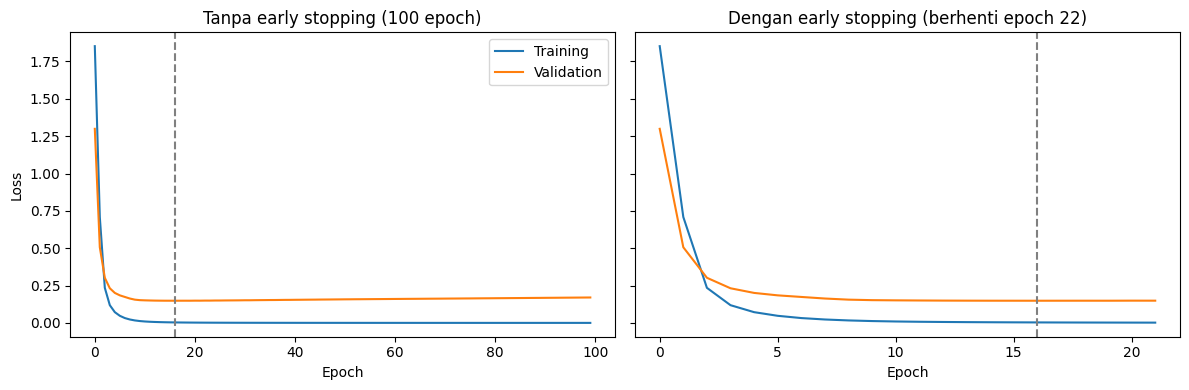

In [9]:
def buat_model():
    m = keras.Sequential([keras.Input(shape=(64,)),
                          keras.layers.Dense(128, activation="relu"),
                          keras.layers.Dense(64, activation="relu"),
                          keras.layers.Dense(32, activation="relu"),
                          keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# Tanpa early stopping (100 epoch)
keras.utils.set_random_seed(42)
model_tanpa = buat_model()
h_tanpa = model_tanpa.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=0)

# Dengan early stopping
keras.utils.set_random_seed(42)
model_es = buat_model()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",
                                           patience=5, restore_best_weights=True)
history = model_es.fit(X_train, y_train, validation_split=0.2,
                       epochs=100, callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:",
      len(history.history["loss"]))
print("Epoch terbaik (val_loss terendah):", int(np.argmin(history.history["val_loss"])) + 1)
print("Akurasi test dengan early stopping :", round(model_es.evaluate(X_test, y_test, verbose=0)[1], 3))
print("Akurasi test tanpa early stopping  :", round(model_tanpa.evaluate(X_test, y_test, verbose=0)[1], 3))
vt = h_tanpa.history["val_loss"]
print("Tanpa ES: val_loss terendah", round(min(vt), 3), "pada epoch", int(np.argmin(vt)) + 1, "| val_loss akhir (epoch 100):", round(vt[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].plot(h_tanpa.history["loss"], label="Training"); ax[0].plot(h_tanpa.history["val_loss"], label="Validation")
ax[0].axvline(int(np.argmin(vt)), ls="--", color="gray"); ax[0].set_title("Tanpa early stopping (100 epoch)")
ax[1].plot(history.history["loss"], label="Training"); ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].axvline(int(np.argmin(history.history["val_loss"])), ls="--", color="gray")
ax[1].set_title(f"Dengan early stopping (berhenti epoch {len(history.history['loss'])})")
for a in ax: a.set_xlabel("Epoch")
ax[0].set_ylabel("Loss"); ax[0].legend(); plt.tight_layout(); plt.show()

In [10]:
# Kestabilan: ulangi dengan 5 seed
rows = []
for s in range(5):
    keras.utils.set_random_seed(s); m1 = buat_model()
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h1 = m1.fit(X_train, y_train, validation_split=0.2, epochs=100, callbacks=[es], verbose=0)
    keras.utils.set_random_seed(s); m2 = buat_model()
    h2 = m2.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=0)
    rows.append({"seed": s, "Epoch berhenti (ES)": len(h1.history["loss"]),
                 "Test acc (ES)": m1.evaluate(X_test, y_test, verbose=0)[1],
                 "Test acc (100 epoch)": m2.evaluate(X_test, y_test, verbose=0)[1],
                 "val_loss min": min(h2.history["val_loss"]), "val_loss akhir (100 epoch)": h2.history["val_loss"][-1]})
tabel_es = pd.DataFrame(rows).round(3)
display(tabel_es)
display(tabel_es.drop(columns="seed").mean().round(3).to_frame("rata-rata").T)

,seed,Epoch berhenti (ES),Test acc (ES),Test acc (100 epoch),val_loss min,val_loss akhir (100 epoch)
0,0,19,0.969,0.978,0.185,0.227
1,1,18,0.972,0.978,0.165,0.196
2,2,18,0.975,0.983,0.121,0.144
3,3,15,0.969,0.975,0.166,0.204
4,4,16,0.969,0.972,0.223,0.319


,Epoch berhenti (ES),Test acc (ES),Test acc (100 epoch),val_loss min,val_loss akhir (100 epoch)
rata-rata,17.2,0.971,0.977,0.172,0.218


#### Kesimpulan Praktikum 2

| | Tanpa early stopping | Dengan early stopping |
|---|---|---|
| Epoch pelatihan (seed 42) | 100 | 22 (epoch terbaik: 17) |
| Test acc (seed 42) | 0,986 | 0,983 |
| Epoch berhenti (5 seed) | 100 | 15–19 (rata-rata 17,2) |
| Test acc rata-rata (5 seed) | 0,977 | 0,971 |
| val_loss | terendah 0,172 → akhir 0,218 | model dikembalikan ke epoch terbaik |

- **Early stopping bekerja sesuai tujuannya:** pelatihan berhenti di sekitar epoch 15–22 (hemat ±80% waktu pelatihan) dan bobot dikembalikan ke epoch dengan val_loss terendah (`restore_best_weights=True`). Tanpa early stopping, val_loss naik dari rata-rata 0,172 menjadi 0,218 pada epoch 100 (training loss terus turun), pertanda overfitting pada sisi *loss*.
- **Catatan jujur tentang akurasi:** akurasi test dengan early stopping justru sedikit lebih rendah (rata-rata 0,971 vs 0,977; selisih ±2 gambar dari 360, dan konsisten pada kelima seed). Artinya kenaikan val_loss terutama menandakan model makin *terlalu yakin* pada prediksi, bukan menurunnya jumlah prediksi yang benar. Pada kasus ini early stopping menghemat waktu dan menjaga loss tetap baik, tetapi tidak meningkatkan akurasi.
- **Saran:** bila tujuan utamanya akurasi, pantau `val_accuracy` (atau naikkan `patience`); bila tujuannya probabilitas yang terkalibrasi, pantau `val_loss` seperti pada contoh buku.